# Credit Default Risk: the Modern Toolkit for Classical ML
**LazyPredict** (screen 25+ models) → **imbalanced-learn** (does resampling help?) → **Optuna** (Bayesian tuning with pruning) → **calibration** → credit-risk metrics (Gini, KS, lift, cut-off strategy) → **300–900 score scaling** → **SHAP** reason codes → **fairlearn** audit → **PSI** stability.

> Data: *Default of Credit Card Clients* (UCI; Yeh & Lien 2009), 30,000 real card holders, CC0 via the Hugging Face Hub (`scikit-learn/credit-card-clients`). Target: default on next month's payment.

In [1]:
import sys, warnings, time
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from credit import *
import charts
raw = load_raw()
df = engineer(clean(raw))
X, y = xy(df)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(df.shape, f'default rate {y.mean():.1%}')
df.head(3)

(30000, 34) default rate 22.1%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,months_delinquent,max_delay_months,recent_delay,utilisation_latest,utilisation_avg,utilisation_trend,payment_ratio_avg,payment_ratio_min,months_no_payment,over_limit_months
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,2,2,2,0.195650,0.064200,0.195650,0.800000,0.000000,5,0
1,120000.0,2,2,2,26,-1,2,0,0,0,...,2,2,0,0.022350,0.023718,-0.004825,0.193583,0.000000,2,0
2,90000.0,2,2,2,34,0,0,0,0,0,...,0,0,0,0.324878,0.188246,0.152111,0.083968,0.064313,0,0


## 1. Data quality and feature engineering
The UCI data dictionary has undocumented codes (EDUCATION 0/5/6, MARRIAGE 0); they are grouped as *other*. Eleven behavioural features are added: delinquency counts, worst delay, utilisation level and trend, share of bill paid, months with no payment, and months over the limit.

In [2]:
pd.crosstab(df.max_delay_months.clip(upper=4), df[TARGET], normalize='index').rename(columns={0: 'paid', 1: 'defaulted'}).round(3)

default,paid,defaulted
max_delay_months,,
0,0.883,0.117
1,0.750,0.250
2,0.564,0.436
3,0.378,0.622
4,0.359,0.641


## 2. LazyPredict: screen every sklearn-compatible classifier with one call

27 models in 224s


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LGBMClassifier,0.8188,0.6564,0.7799,0.7979,0.8013,0.8188,0.4342
CatBoostClassifier,0.8165,0.6576,0.7783,0.7970,0.7984,0.8165,6.3316
AdaBoostClassifier,0.8197,0.6441,0.7682,0.7938,0.8036,0.8197,2.8881
LogisticRegression,0.8145,0.6451,0.7625,0.7912,0.7954,0.8145,0.3928
XGBClassifier,0.8096,0.6520,0.7624,0.7909,0.7898,0.8096,0.4786
RandomForestClassifier,0.8132,0.6557,0.7606,0.7943,0.7943,0.8132,7.8889
CalibratedClassifierCV,0.8140,0.6400,0.7600,0.7889,0.7948,0.8140,1.0532
LinearSVC,0.8129,0.6358,0.7600,0.7867,0.7933,0.8129,0.3579
RidgeClassifierCV,0.8115,0.6315,0.7578,0.7840,0.7913,0.8115,0.1130


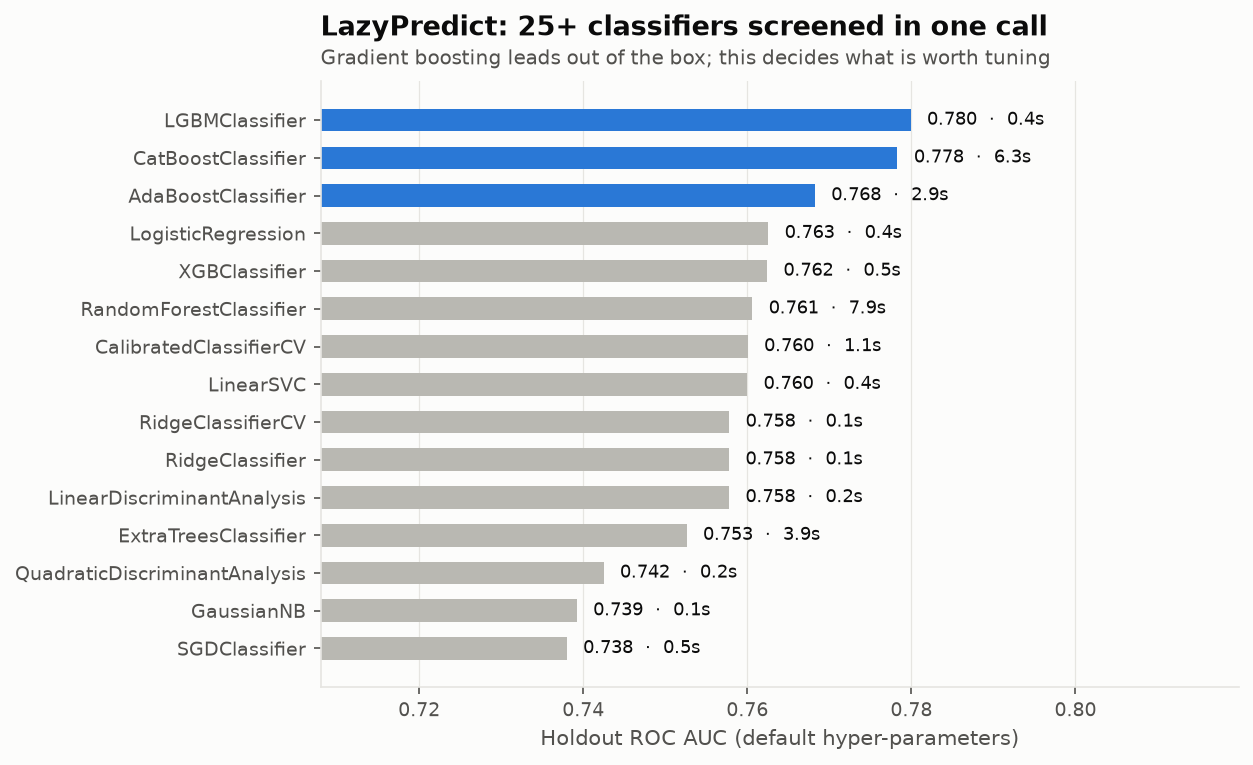

In [3]:
from lazypredict.Supervised import LazyClassifier
t = time.time()
lb, _ = LazyClassifier(verbose=0, ignore_warnings=True, random_state=SEED).fit(X_tr, X_te, y_tr, y_te)
lb = lb.sort_values('ROC AUC', ascending=False)
print(f'{len(lb)} models in {time.time() - t:.0f}s')
charts.lazypredict_chart(lb)
lb.to_csv('../reports/lazypredict_leaderboard.csv')
display(lb.head(12).round(4))
display(Image('../images/lazypredict_leaderboard.png'))

## 3. Class imbalance: does SMOTE help?
22% defaulters. Compare LightGBM as-is, with class weights, and with SMOTE inside the CV pipeline (resampling must happen *inside* each fold, never before the split). 3-fold CV keeps the notebook CPU-friendly.

In [4]:
import lightgbm as lgb
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import average_precision_score
base = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, verbose=-1, random_state=SEED)
variants = {'As-is': lgb.LGBMClassifier(**base),
            'Class weights': lgb.LGBMClassifier(**base, class_weight='balanced'),
            'SMOTE': ImbPipeline([('smote', SMOTE(random_state=SEED)), ('m', lgb.LGBMClassifier(**base))])}
cv = StratifiedKFold(3, shuffle=True, random_state=SEED)
rows, probs = [], {}
for name, m in variants.items():
    auc = cross_val_score(m, X_tr, y_tr, cv=cv, scoring='roc_auc').mean()
    p = m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]; probs[name] = p
    rows.append({'variant': name, 'cv_roc_auc': auc, 'holdout_pr_auc': average_precision_score(y_te, p),
                 'mean_predicted_pd': p.mean(), 'actual_default_rate': y_te.mean(), 'brier': brier_score_loss(y_te, p)})
imb = pd.DataFrame(rows).set_index('variant').round(4)
imb

,cv_roc_auc,holdout_pr_auc,mean_predicted_pd,actual_default_rate,brier
variant,,,,,
As-is,0.7806,0.5570,0.2220,0.2212,0.1351
Class weights,0.7799,0.5568,0.3968,0.2212,0.1735
SMOTE,0.7577,0.5214,0.3189,0.2212,0.1554


**Lesson:** ranking power (AUC) barely moves, but SMOTE and class weights **inflate predicted PDs**. In credit risk the probabilities themselves are used for pricing and provisioning, so the as-is model plus a decision threshold is preferred.

## 4. Optuna: Bayesian hyper-parameter search with pruning

In [5]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    params = dict(n_estimators=trial.suggest_int('n_estimators', 200, 700, step=100),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True), num_leaves=trial.suggest_int('num_leaves', 8, 96),
        min_child_samples=trial.suggest_int('min_child_samples', 10, 200), subsample=trial.suggest_float('subsample', 0.5, 1.0),
        subsample_freq=1, colsample_bytree=trial.suggest_float('colsample_bytree', 0.4, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 30, log=True), verbose=-1, random_state=SEED)
    scores = []
    for k, (a, b) in enumerate(cv.split(X_tr, y_tr)):
        m = lgb.LGBMClassifier(**params).fit(X_tr.iloc[a], y_tr.iloc[a])
        scores.append(roc_auc_score(y_tr.iloc[b], m.predict_proba(X_tr.iloc[b])[:, 1]))
        trial.report(np.mean(scores), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(scores)
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED), pruner=optuna.pruners.MedianPruner(n_warmup_steps=2))
t = time.time(); study.optimize(objective, n_trials=20)
pruned = sum(t_.state == optuna.trial.TrialState.PRUNED for t_ in study.trials)
print(f'best CV AUC {study.best_value:.4f} after {len(study.trials)} trials ({pruned} pruned) in {time.time() - t:.0f}s')
study.best_params

best CV AUC 0.7884 after 20 trials (13 pruned) in 100s


{'n_estimators': 200,
 'learning_rate': 0.019594972058679168,
 'num_leaves': 40,
 'min_child_samples': 97,
 'subsample': 0.8925879806965068,
 'colsample_bytree': 0.5198042692950159,
 'reg_lambda': 0.20058106556780586}

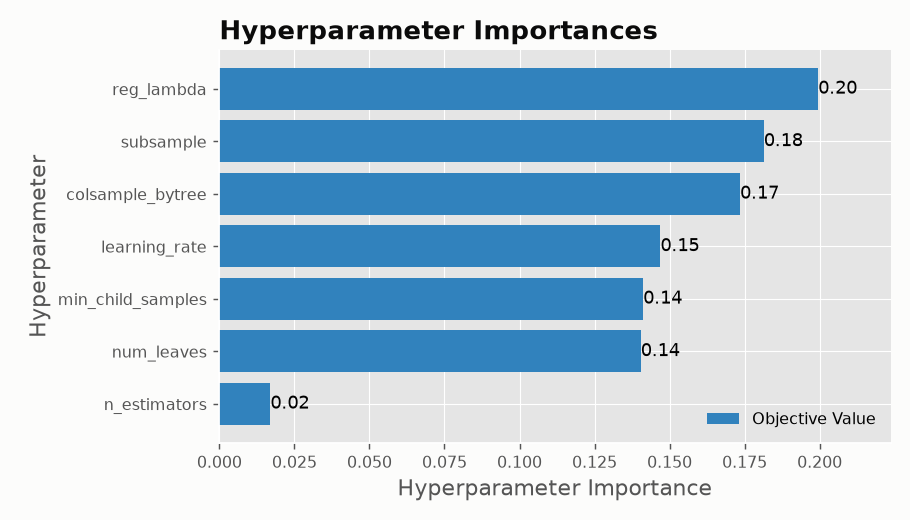

In [6]:
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
charts.apply_style()
ax = plot_param_importances(study); ax.figure.set_size_inches(7, 4); ax.figure.tight_layout()
ax.figure.savefig('../images/optuna_param_importance.png', dpi=130); plt.close(ax.figure)
ax = plot_optimization_history(study); ax.figure.set_size_inches(7, 4); ax.figure.tight_layout()
ax.figure.savefig('../images/optuna_history.png', dpi=130); plt.close(ax.figure)
plt.style.use('default'); charts.apply_style()   # optuna switched the global style to ggplot
display(Image('../images/optuna_param_importance.png'))

## 5. Holdout comparison: interpretable baseline vs tuned boosting vs CatBoost/XGBoost

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
tuned = lgb.LGBMClassifier(**study.best_params, subsample_freq=1, verbose=-1, random_state=SEED).fit(X_tr, y_tr)
models = {'Logistic regression (scorecard-style)': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_tr, y_tr),
          'XGBoost (defaults)': XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, random_state=SEED).fit(X_tr, y_tr),
          'CatBoost (defaults)': CatBoostClassifier(verbose=0, random_seed=SEED).fit(X_tr, y_tr),
          'LightGBM (Optuna-tuned)': tuned}
calibrated = CalibratedClassifierCV(lgb.LGBMClassifier(**study.best_params, subsample_freq=1, verbose=-1, random_state=SEED), method='isotonic', cv=3).fit(X_tr, y_tr)
models['LightGBM tuned + isotonic calibration'] = calibrated
P = {k: m.predict_proba(X_te)[:, 1] for k, m in models.items()}
results = pd.DataFrame([metric_row(k, y_te, p) for k, p in P.items()]).set_index('model').round(4)
results.to_csv('../reports/holdout_results.csv')
results

,roc_auc,gini,ks,brier
model,,,,
Logistic regression (scorecard-style),0.7625,0.5251,0.4010,0.1387
XGBoost (defaults),0.7794,0.5587,0.4274,0.1347
CatBoost (defaults),0.7797,0.5594,0.4288,0.1354
LightGBM (Optuna-tuned),0.7826,0.5652,0.4272,0.1339
LightGBM tuned + isotonic calibration,0.7820,0.5640,0.4270,0.1343


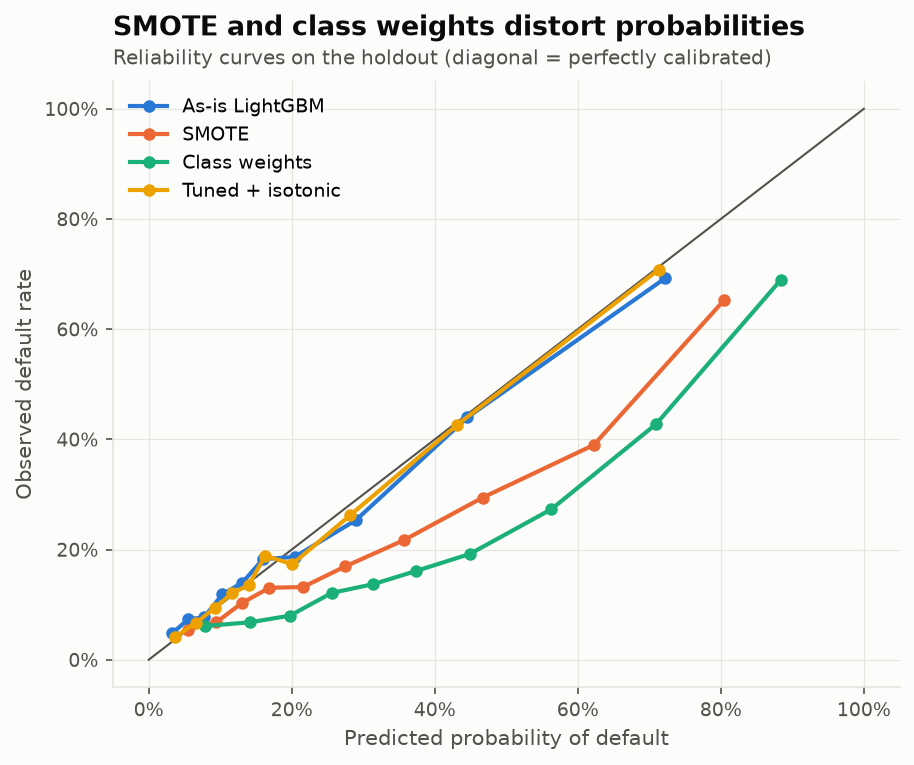

In [8]:
curves = {k: calibration_curve(y_te, p, n_bins=10, strategy='quantile') for k, p in
          {'As-is LightGBM': probs['As-is'], 'SMOTE': probs['SMOTE'], 'Class weights': probs['Class weights'],
           'Tuned + isotonic': P['LightGBM tuned + isotonic calibration']}.items()}
charts.calibration_chart({k: (v[1], v[0]) for k, v in curves.items()})
display(Image('../images/calibration.png'))

## 6. Credit-risk view: gains, cut-off and a 300–900 score

In [9]:
pd_final = P['LightGBM tuned + isotonic calibration']
gains = gains_table(y_te, pd_final)
gains.to_csv('../reports/gains_table.csv')
gains

,customers,defaulters,avg_pd,bad_rate_pct,cum_defaulters_captured_pct,lift
decile,,,,,,
1,750,531,0.713,70.800,32.007,3.201
2,750,319,0.431,42.533,51.236,1.923
3,750,196,0.280,26.133,63.050,1.181
4,750,129,0.200,17.200,70.826,0.778
5,750,142,0.163,18.933,79.385,0.856
6,750,101,0.139,13.467,85.473,0.609
7,750,91,0.116,12.133,90.958,0.549
8,750,68,0.092,9.067,95.057,0.410
9,750,51,0.066,6.800,98.131,0.307


,approval_rate_pct,bad_rate_pct,profit_index
0,20,5.40,16.22
1,25,5.87,19.44
2,30,6.62,21.70
3,35,7.20,23.86
4,40,7.97,25.04
5,45,8.39,26.82
6,50,9.12,27.15
7,55,9.92,26.72
8,60,10.74,25.62
9,65,11.16,25.76


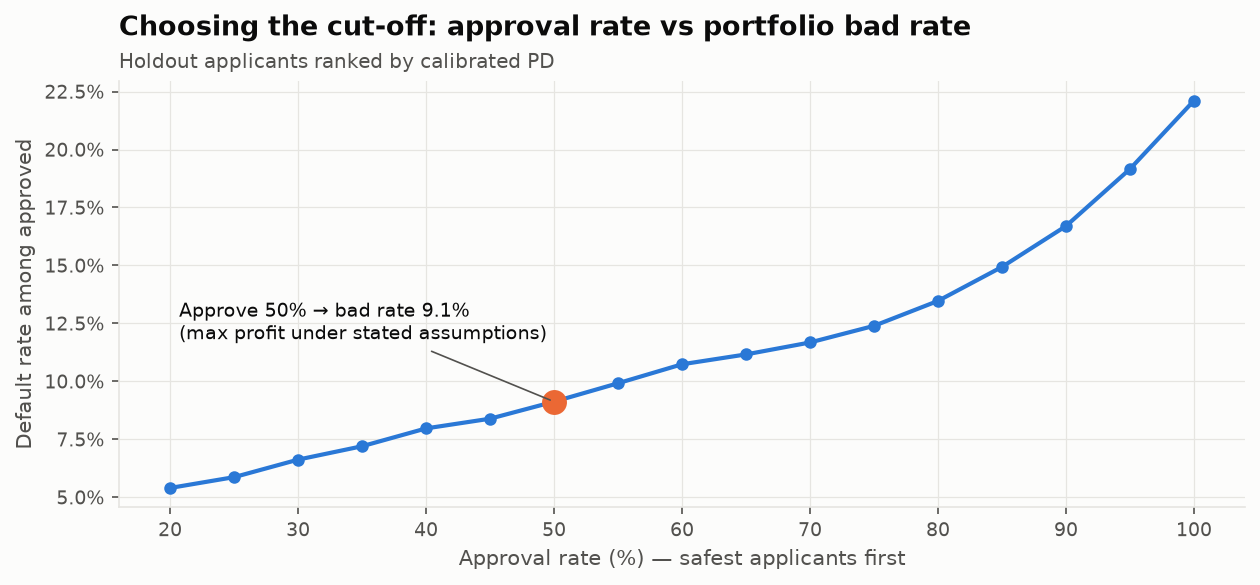

In [10]:
cut = cutoff_strategy(y_te, pd_final)
best = int(cut.loc[cut.profit_index.idxmax(), 'approval_rate_pct'])
threshold = np.quantile(pd_final, best / 100)
charts.cutoff_chart(cut, best)
display(cut.round(2))
display(Image('../images/cutoff_strategy.png'))

,customers,share_pct,default_rate_pct
band,,,
300-550,1665,22.20,54.65
551-600,1277,17.03,20.20
601-650,2442,32.56,14.66
651-700,1394,18.59,7.60
701-750,563,7.51,3.91
751-900,159,2.12,3.14


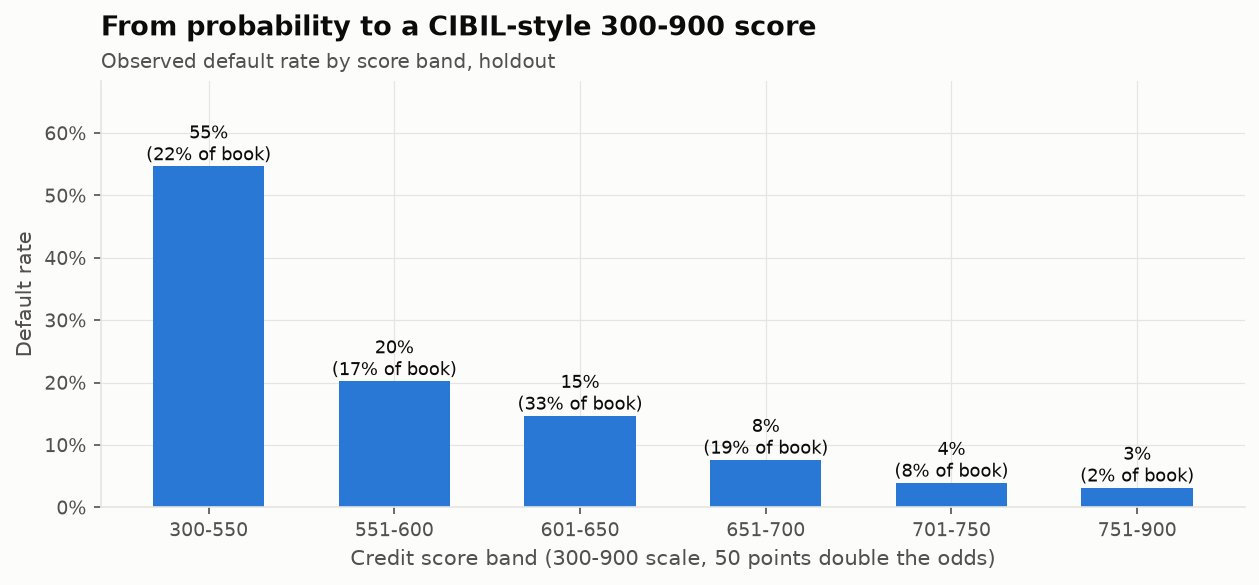

In [11]:
scores = pd_to_score(pd_final)
bands = score_bands(y_te, scores)
charts.score_band_chart(bands)
display(bands)
display(Image('../images/score_bands.png'))

## 7. SHAP: global drivers and per-applicant reason codes

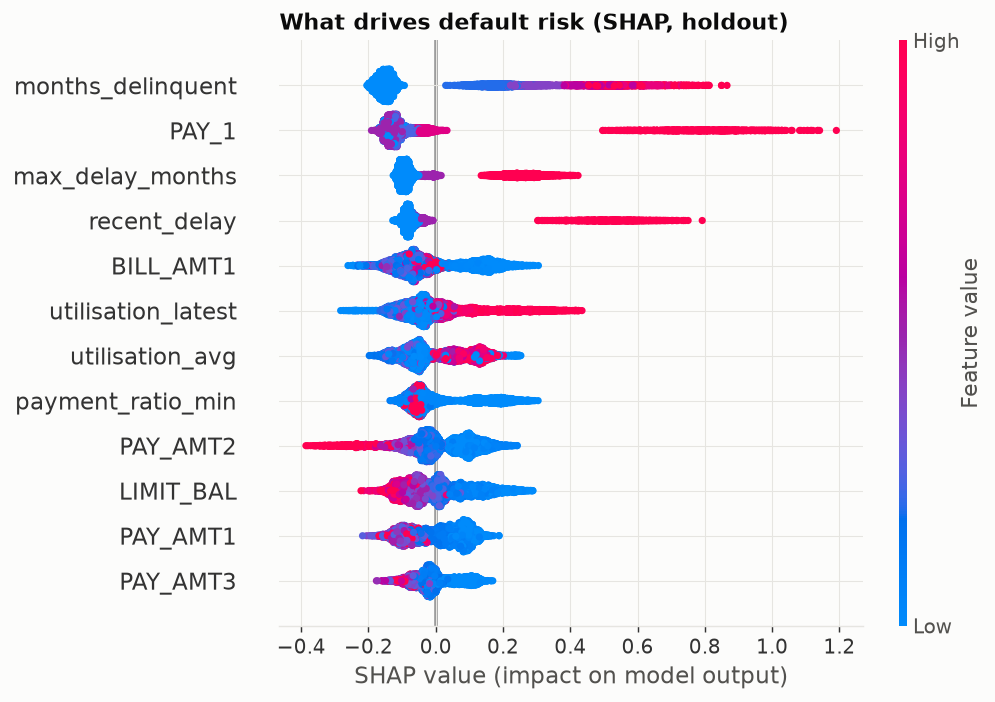

In [12]:
import shap
explainer = shap.TreeExplainer(tuned)
sv = explainer.shap_values(X_te)
sv = sv[1] if isinstance(sv, list) else sv
plt.figure()
shap.summary_plot(sv, X_te, max_display=12, show=False, plot_size=(8, 5.5))
plt.title('What drives default risk (SHAP, holdout)', loc='left', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../images/shap_summary.png', dpi=130, bbox_inches='tight'); plt.close()
display(Image('../images/shap_summary.png'))

In [13]:
# reason codes for six declined applicants spread from borderline to highest risk
declined_idx = np.flatnonzero(pd_final > threshold)
declined = declined_idx[np.argsort(pd_final[declined_idx])][np.linspace(0, len(declined_idx) - 1, 6).astype(int)]
reasons = reason_codes(sv[declined], list(X_te.columns))
pd.DataFrame({'score': scores[declined], 'pd': pd_final[declined].round(3), 'principal_reasons': ['; '.join(r) for r in reasons]})

,score,pd,principal_reasons
0,616,0.150,Average credit utilisation; Latest bill amount...
1,602,0.178,Latest bill amount; PAY_AMT2; Last payment amount
2,578,0.232,Worst payment delay (6 months); Months with a ...
3,542,0.332,Worst payment delay (6 months); Months with a ...
4,465,0.592,Payment delay last month; Payment delay last m...
5,300,0.983,Payment delay last month; Months with a late p...


## 8. Fairness audit (fairlearn)
Sex and age are **not** model inputs for the decision in many jurisdictions. Here they are used only to audit outcomes at the chosen cut-off.

Sex approval-rate ratio (min/max): 0.902
Age approval-rate ratio (min/max): 0.827


,approval_rate,true_positive_rate,false_positive_rate
Sex: Female,0.523,0.780,0.396
Sex: Male,0.472,0.809,0.442
Age: 30-45,0.532,0.775,0.387
Age: 45+,0.440,0.816,0.472
Age: <30,0.492,0.800,0.425


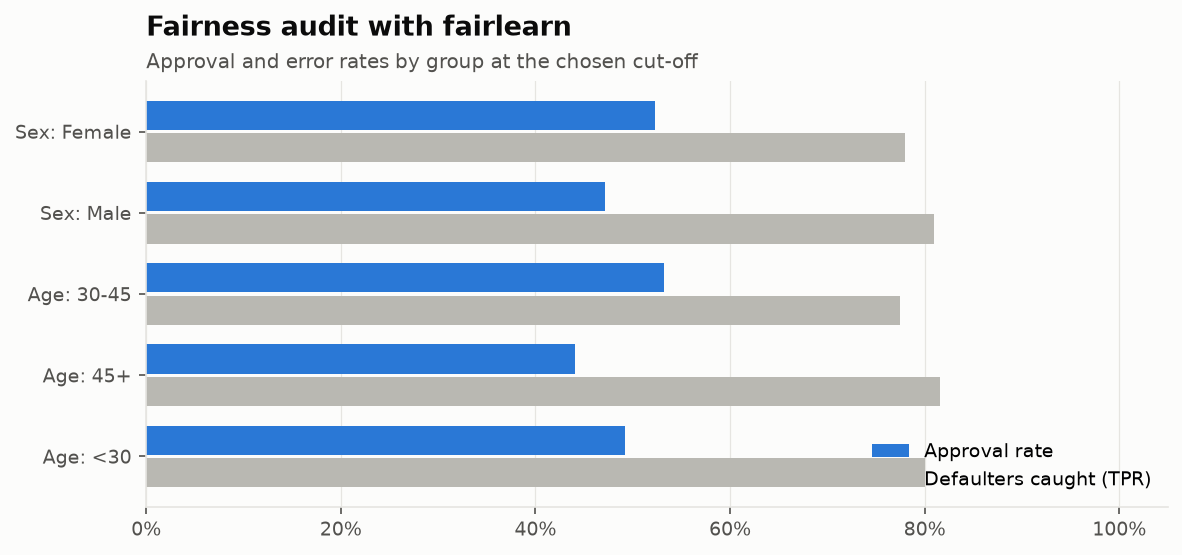

In [14]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_ratio
threshold = np.quantile(pd_final, best / 100)
approve = (pd_final <= threshold).astype(int)
groups = pd.DataFrame({'Sex': X_te.SEX.map({1: 'Male', 2: 'Female'}).to_numpy(),
                       'Age': pd.cut(X_te.AGE, [0, 30, 45, 120], labels=['<30', '30-45', '45+']).astype(str).to_numpy()})
frames = {}
for g in groups:
    mf = MetricFrame(metrics={'approval_rate': selection_rate, 'true_positive_rate': true_positive_rate, 'false_positive_rate': false_positive_rate},
                     y_true=y_te, y_pred=1 - approve, sensitive_features=groups[g])
    t = mf.by_group.copy(); t['approval_rate'] = 1 - t['approval_rate']; t.index = [f'{g}: {i}' for i in t.index]; frames[g] = t
    print(g, 'approval-rate ratio (min/max):', round(t.approval_rate.min() / t.approval_rate.max(), 3))
fair = pd.concat(frames.values())
charts.fairness_chart(fair)
display(fair.round(3))
display(Image('../images/fairness.png'))

## 9. Stability: Population Stability Index

In [15]:
pd_train = calibrated.predict_proba(X_tr)[:, 1]
print(f'PSI train vs holdout scores: {psi(pd_train, pd_final):.4f}  (< 0.1 = stable)')
# stress the RAW inputs, then rebuild the engineered features (perturbing X directly would leave derived features stale)
stressed = clean(raw).loc[X_te.index].copy()
stressed['LIMIT_BAL'] = stressed.LIMIT_BAL * 0.7
late = np.random.default_rng(0).random(len(stressed)) < 0.15
stressed.loc[late, 'PAY_1'] = stressed.loc[late, 'PAY_1'].clip(lower=0) + 2
drift = xy(engineer(stressed))[0][X_te.columns]
pd_stress = calibrated.predict_proba(drift)[:, 1]
print(f'PSI under a stress scenario (limits cut 30%, 15% of customers 2 months late): {psi(pd_final, pd_stress):.3f}  '
      f'(mean PD {pd_final.mean():.1%} -> {pd_stress.mean():.1%})')

PSI train vs holdout scores: 0.0010  (< 0.1 = stable)
PSI under a stress scenario (limits cut 30%, 15% of customers 2 months late): 0.127  (mean PD 22.4% -> 29.2%)


## 10. Model card

In [16]:
card = pd.Series({'Model': 'LightGBM (Optuna-tuned) + isotonic calibration', 'Training rows': len(X_tr), 'Holdout rows': len(X_te),
    'Holdout ROC AUC': round(results.loc['LightGBM tuned + isotonic calibration', 'roc_auc'], 4),
    'Gini': round(results.loc['LightGBM tuned + isotonic calibration', 'gini'], 4), 'KS': round(results.loc['LightGBM tuned + isotonic calibration', 'ks'], 4),
    'Brier': round(results.loc['LightGBM tuned + isotonic calibration', 'brier'], 4), 'Recommended cut-off': f'approve safest {best}%',
    'Top-decile capture': f"{gains.cum_defaulters_captured_pct.iloc[0]:.1f}% of defaulters", 'PSI (train vs holdout)': round(psi(pd_train, pd_final), 4),
    'Known limits': 'Taiwan 2005 card data; no bureau/income fields; sex & age used only for auditing'})
card.to_frame('value').to_csv('../reports/model_card.csv')
card.to_frame('value')

,value
Model,LightGBM (Optuna-tuned) + isotonic calibration
Training rows,22500
Holdout rows,7500
Holdout ROC AUC,0.782
Gini,0.564
KS,0.427
Brier,0.1343
Recommended cut-off,approve safest 50%
Top-decile capture,32.0% of defaulters
PSI (train vs holdout),0.001
